### 이진 분류

In [128]:
### 이진 분류

In [129]:
import torch
import matplotlib.pyplot as plt

In [130]:
N = 20

random0 = torch.randn(int(N/2), 1)
random5 = torch.randn(int(N/2), 1)+5

print('0: \n',random0)
print('5: \n',random5)

0: 
 tensor([[-0.0650],
        [ 0.8057],
        [ 0.7800],
        [ 0.4789],
        [ 0.3176],
        [-0.4437],
        [-1.1768],
        [-0.1989],
        [ 0.3965],
        [-0.5585]])
5: 
 tensor([[4.2214],
        [4.2470],
        [4.8101],
        [6.5471],
        [3.9509],
        [4.3063],
        [3.9135],
        [4.9407],
        [4.2409],
        [6.1318]])


In [131]:
#data
class1_data = torch.hstack([random0, random5])
class2_data = torch.hstack([random5, random0])
print(class1_data)
print(class2_data)

#label
class1_label = torch.ones(int(N/2),1)
class2_label = torch.zeros(int(N/2), 1)

x = torch.vstack([class1_data, class2_data]) #20행 2열
y = torch.vstack([class1_label, class2_label]) #20행 1열
print(x)
print(y)


tensor([[-0.0650,  4.2214],
        [ 0.8057,  4.2470],
        [ 0.7800,  4.8101],
        [ 0.4789,  6.5471],
        [ 0.3176,  3.9509],
        [-0.4437,  4.3063],
        [-1.1768,  3.9135],
        [-0.1989,  4.9407],
        [ 0.3965,  4.2409],
        [-0.5585,  6.1318]])
tensor([[ 4.2214, -0.0650],
        [ 4.2470,  0.8057],
        [ 4.8101,  0.7800],
        [ 6.5471,  0.4789],
        [ 3.9509,  0.3176],
        [ 4.3063, -0.4437],
        [ 3.9135, -1.1768],
        [ 4.9407, -0.1989],
        [ 4.2409,  0.3965],
        [ 6.1318, -0.5585]])
tensor([[-0.0650,  4.2214],
        [ 0.8057,  4.2470],
        [ 0.7800,  4.8101],
        [ 0.4789,  6.5471],
        [ 0.3176,  3.9509],
        [-0.4437,  4.3063],
        [-1.1768,  3.9135],
        [-0.1989,  4.9407],
        [ 0.3965,  4.2409],
        [-0.5585,  6.1318],
        [ 4.2214, -0.0650],
        [ 4.2470,  0.8057],
        [ 4.8101,  0.7800],
        [ 6.5471,  0.4789],
        [ 3.9509,  0.3176],
        [ 4.3063, 

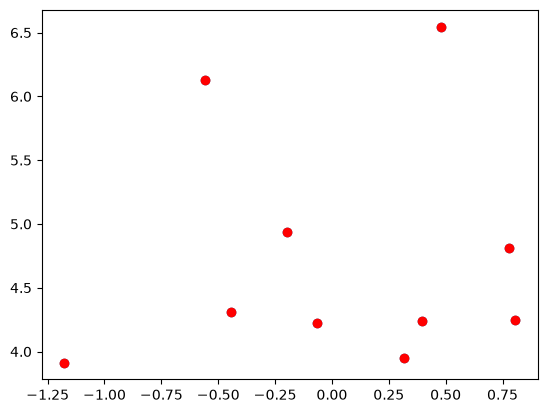

In [132]:
plt.plot(class1_data[:,0], class1_data[:,1], 'o')
plt.plot(class1_data[:,0], class1_data[:,1], 'ro')

Step2. 모델 만들기

In [133]:
from torch import nn

class MLP(nn.Module):
    def __init__(self) :
        super().__init__()

        # self.linear = nn.Sequential(nn.Linear(2, 200),
        #                             nn.Sigmoid(),
        #                             nn.Linear(200, 1),
        #                             nn.Sigmoid()
                                    # )
        # self.linear = nn.Sequential(nn.Linear(2, 1),
        #                             nn.Sigmoid()
        #                             )
        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid(),
                                    )
        
    def forward(self, x):
        x = self.linear(x)
        return x

In [134]:
model = MLP()
print(model)

b = model(torch.randn(5,2))
print(b.shape)



MLP(
  (linear): Sequential(
    (0): Linear(in_features=2, out_features=100, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=100, out_features=100, bias=True)
    (3): Sigmoid()
    (4): Linear(in_features=100, out_features=100, bias=True)
    (5): Sigmoid()
    (6): Linear(in_features=100, out_features=1, bias=True)
    (7): Sigmoid()
  )
)
torch.Size([5, 1])


### step3. 모델 학습시키기

In [135]:
from torch import optim


LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr=LR)
# optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train() #train mode로 전환
for ep in range(EPOCH):
    #예측값
    y_hat = model(x)

    #loss 구하기
    loss = criterion(y_hat, y)

    #update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    #print
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1}, train loss :{loss.item():.4f}')
    print('---------------')

Epoch : 1, train loss :0.7020
---------------
Epoch : 2, train loss :0.6947
---------------
Epoch : 3, train loss :0.6938
---------------
Epoch : 4, train loss :0.6936
---------------
Epoch : 5, train loss :0.6934
---------------
Epoch : 6, train loss :0.6933
---------------
Epoch : 7, train loss :0.6932
---------------
Epoch : 8, train loss :0.6930
---------------
Epoch : 9, train loss :0.6929
---------------
Epoch : 10, train loss :0.6928
---------------
Epoch : 11, train loss :0.6926
---------------
Epoch : 12, train loss :0.6925
---------------
Epoch : 13, train loss :0.6924
---------------
Epoch : 14, train loss :0.6922
---------------
Epoch : 15, train loss :0.6921
---------------
Epoch : 16, train loss :0.6920
---------------
Epoch : 17, train loss :0.6919
---------------
Epoch : 18, train loss :0.6917
---------------
Epoch : 19, train loss :0.6916
---------------
Epoch : 20, train loss :0.6915
---------------
Epoch : 21, train loss :0.6913
---------------
Epoch : 22, train loss

Epoch : 37, train loss :0.6891
---------------
Epoch : 38, train loss :0.6889
---------------
Epoch : 39, train loss :0.6888
---------------
Epoch : 40, train loss :0.6886
---------------
Epoch : 41, train loss :0.6885
---------------
Epoch : 42, train loss :0.6883
---------------
Epoch : 43, train loss :0.6882
---------------
Epoch : 44, train loss :0.6880
---------------
Epoch : 45, train loss :0.6879
---------------
Epoch : 46, train loss :0.6877
---------------
Epoch : 47, train loss :0.6876
---------------
Epoch : 48, train loss :0.6874
---------------
Epoch : 49, train loss :0.6873
---------------
Epoch : 50, train loss :0.6871
---------------
Epoch : 51, train loss :0.6869
---------------
Epoch : 52, train loss :0.6868
---------------
Epoch : 53, train loss :0.6866
---------------
Epoch : 54, train loss :0.6864
---------------
Epoch : 55, train loss :0.6863
---------------
Epoch : 56, train loss :0.6861
---------------
Epoch : 57, train loss :0.6859
---------------
Epoch : 58, t

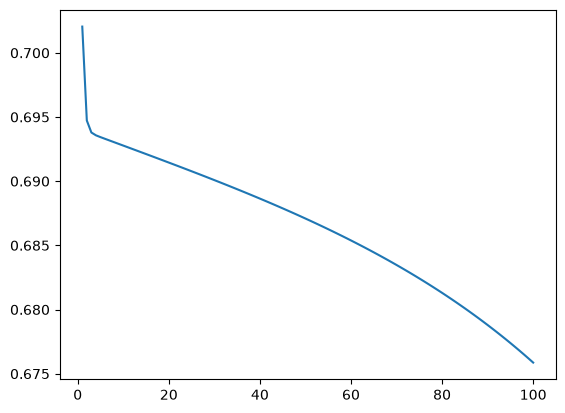

In [136]:
plt.plot(range(1, EPOCH+1), loss_history)